In [ ]:
# ==========================================
# 1. IMPORT LIBRARY
# ==========================================

# Install pytesseract and tesseract-ocr
!pip install pytesseract
!sudo apt update
!sudo apt install tesseract-ocr

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
import pytesseract

# Jika menggunakan Google Colab
from google.colab import files

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
8 packages can be upgraded. Run 'apt list --upgradable' to see them.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newes

In [ ]:
# ==========================================
# 2. DAFTAR FILE IJAZAH
# ==========================================

nama_file = [
    "/content/1.jpeg",
    "/content/2.jpeg",
    "/content/3.jpeg",
    "/content/4.jpeg",
    "/content/5.jpeg",
    "/content/6.jpeg",
    "/content/7.jpeg",
    "/content/8.jpeg",
    "/content/9.jpeg"
]

print("Jumlah file:", len(nama_file))

for file in nama_file:
    print(file, "->", os.path.exists(file))

Jumlah file: 9
/content/1.jpeg -> True
/content/2.jpeg -> True
/content/3.jpeg -> True
/content/4.jpeg -> True
/content/5.jpeg -> True
/content/6.jpeg -> True
/content/7.jpeg -> True
/content/8.jpeg -> True
/content/9.jpeg -> True


In [ ]:
# ==========================================
# 3. CROP AREA NOMOR IJAZAH + GRAYSCALE
# ==========================================

hasil_crop = {}

for i, file in enumerate(nama_file, start=1):

    # Membaca gambar
    img = cv2.imread(file)

    # Memutar gambar 90 derajat searah jarum jam
    img = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)

    # Crop area nomor ijazah
    # Koordinat disesuaikan dengan gambar yang diberikan
    crop = img[800:855, 70:510]

    # Mengubah hasil crop menjadi grayscale
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)

    # Menyimpan hasil
    hasil_crop[i] = gray

print("Crop dan grayscale selesai.")

Crop dan grayscale selesai.


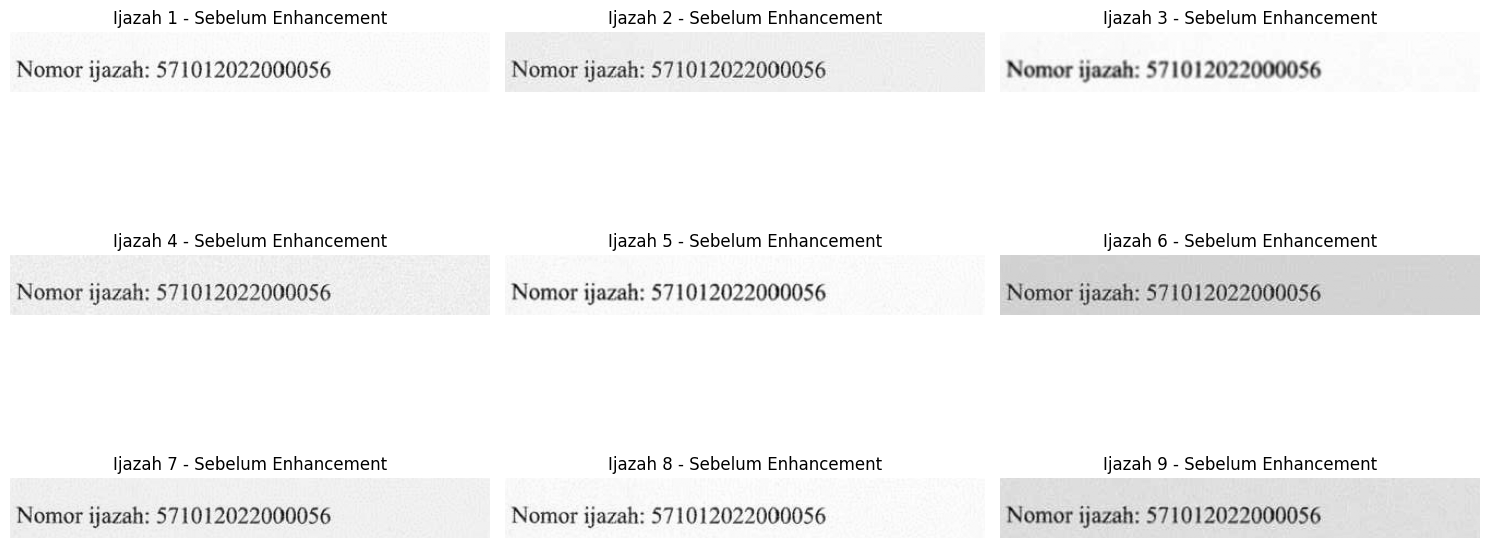

In [ ]:
# ==========================================
# 4. MENAMPILKAN CITRA SEBELUM ENHANCEMENT
# ==========================================

fig, axes = plt.subplots(3, 3, figsize=(15, 8))

for i, ax in enumerate(axes.ravel(), start=1):

    ax.imshow(hasil_crop[i], cmap='gray')
    ax.set_title(f"Ijazah {i} - Sebelum Enhancement")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 5. ENHANCEMENT
# ==========================================

brightness_result = {}
contrast_result = {}
histogram_result = {}

for i, gray in hasil_crop.items():

    # --------------------------------------
    # A. BRIGHTNESS ADJUSTMENT
    # --------------------------------------
    # beta = 30 -> menambah tingkat kecerahan
    brightness = cv2.convertScaleAbs(
        gray,
        alpha=1.0,
        beta=30
    )

    # --------------------------------------
    # B. CONTRAST STRETCHING
    # --------------------------------------
    contrast = cv2.normalize(
        gray,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    # --------------------------------------
    # C. HISTOGRAM EQUALIZATION
    # --------------------------------------
    histogram = cv2.equalizeHist(gray)

    # Simpan hasil
    brightness_result[i] = brightness
    contrast_result[i] = contrast
    histogram_result[i] = histogram

print("Semua enhancement selesai.")

Semua enhancement selesai.


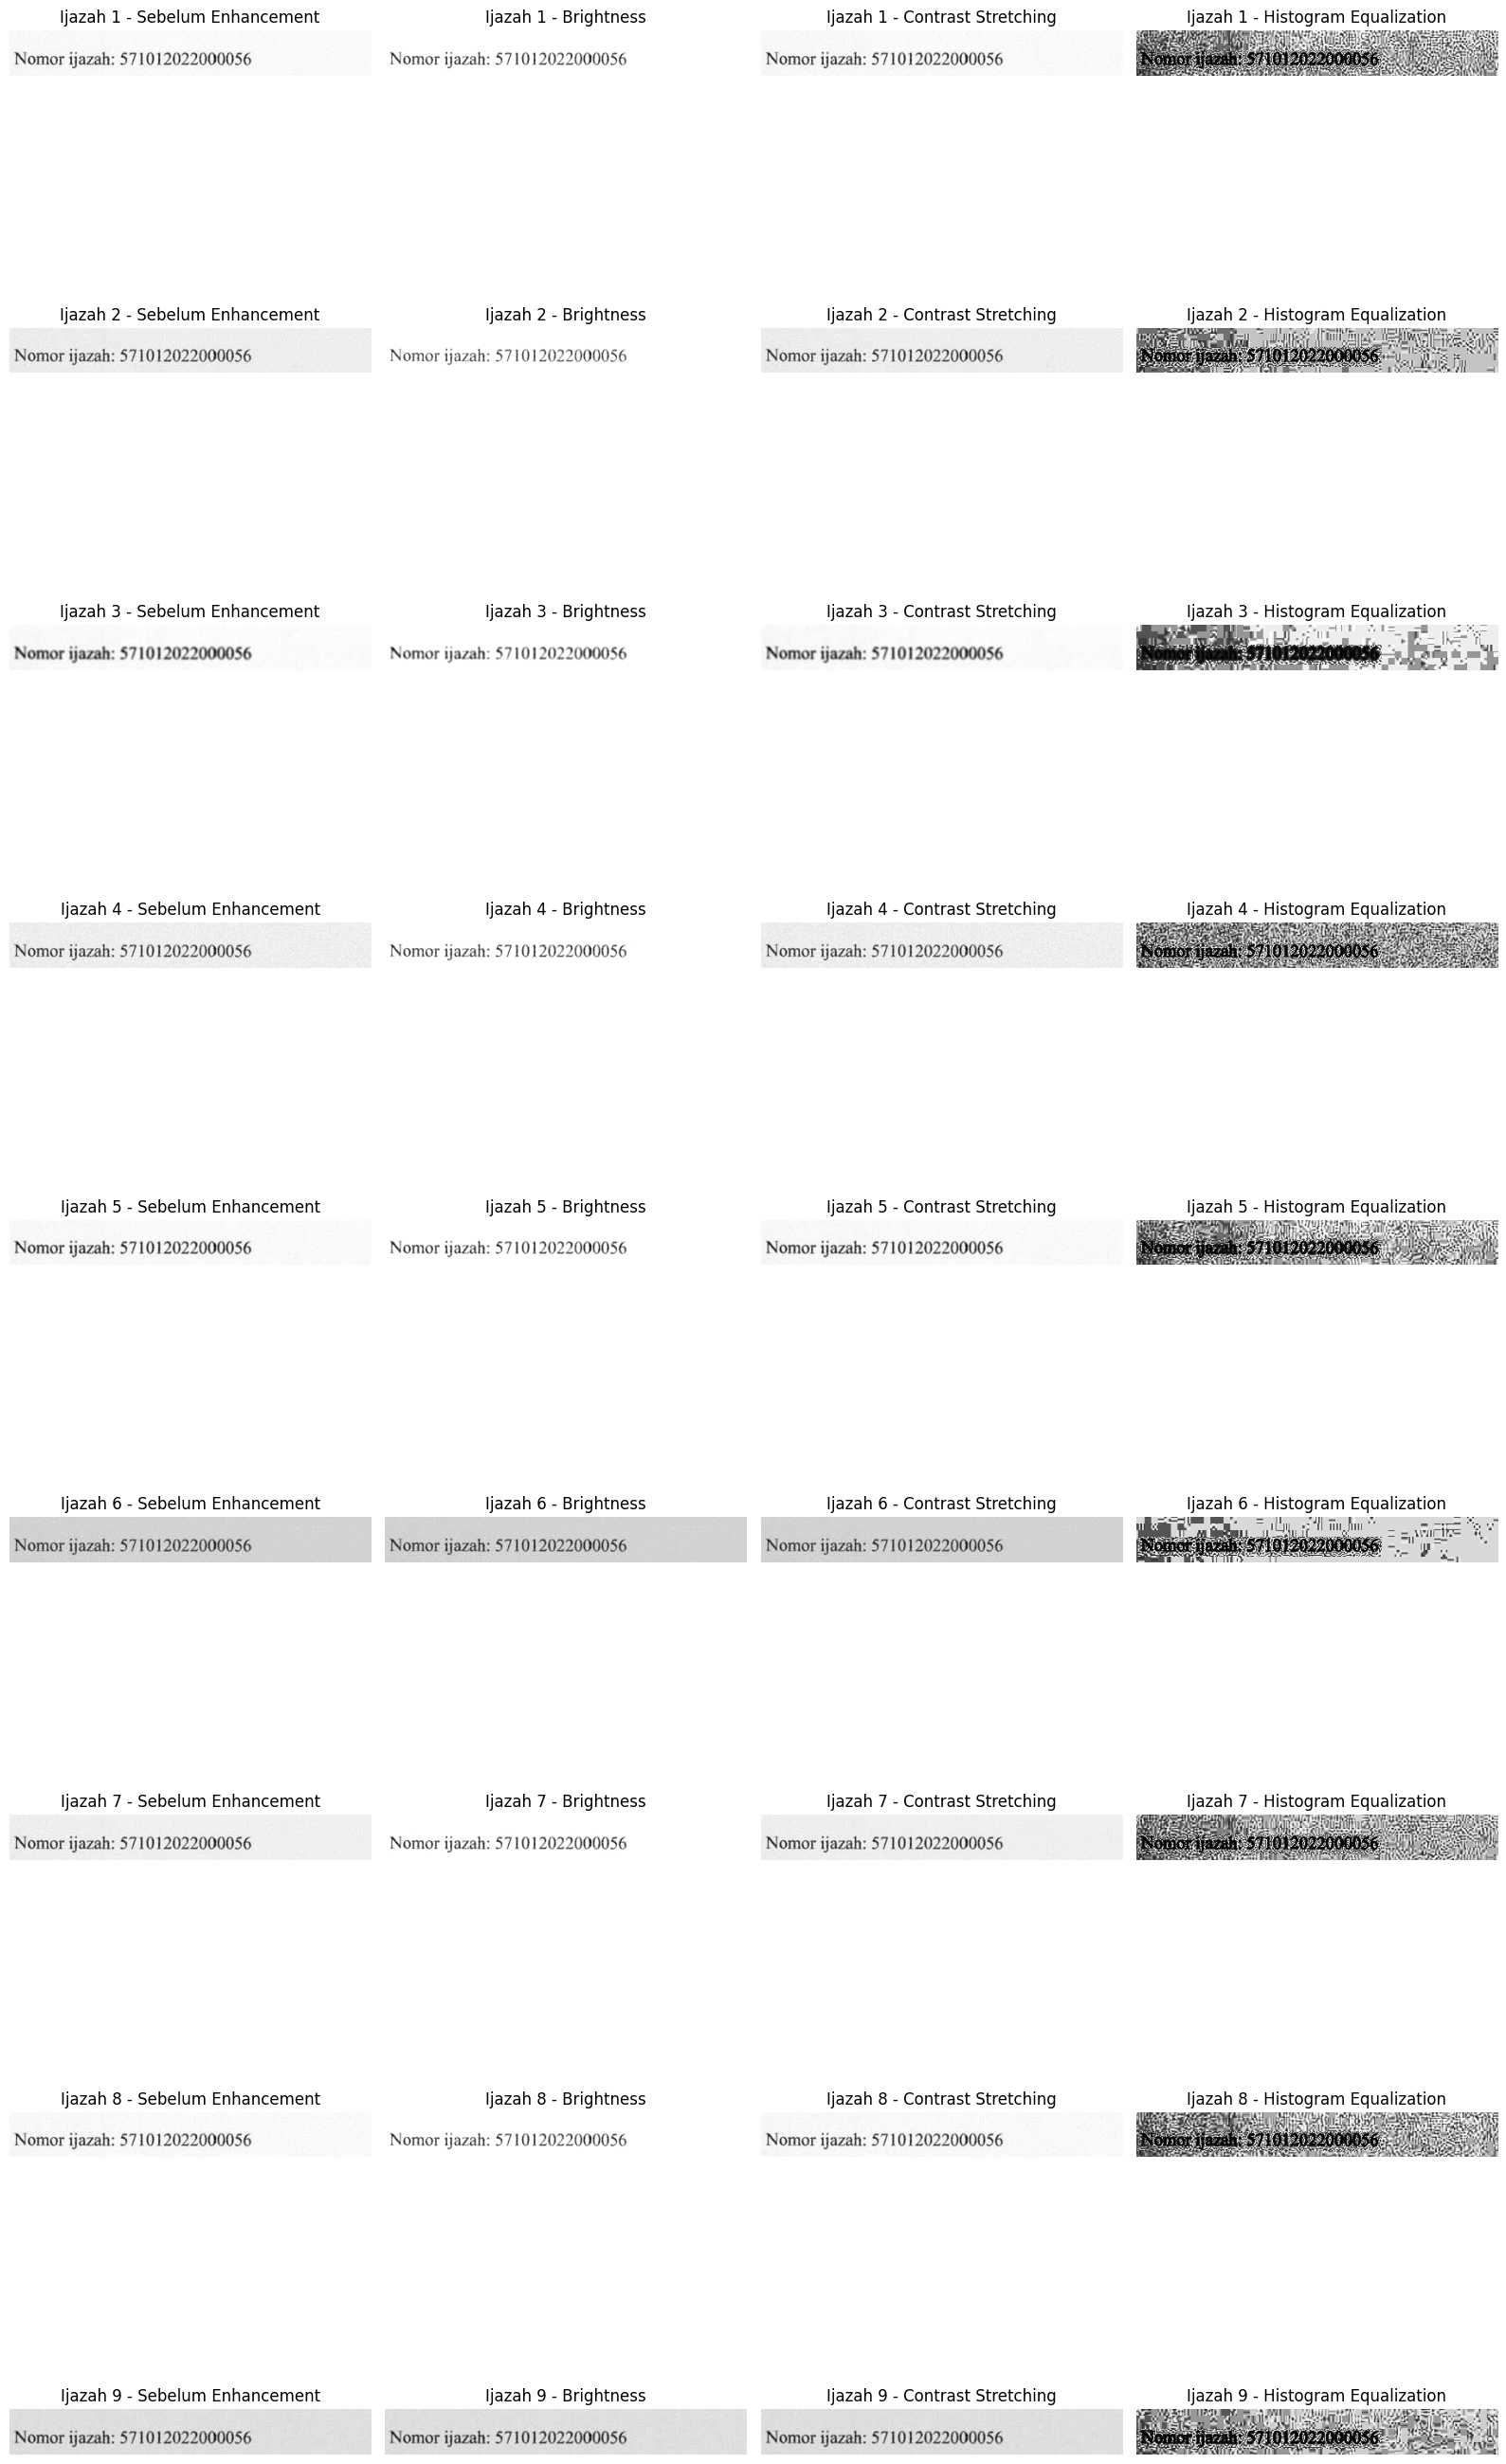

In [ ]:
# ==========================================
# 6. PERBANDINGAN SEBELUM DAN SESUDAH
#    SEMUA IJAZAH 1 SAMPAI 9
# ==========================================

plt.figure(figsize=(16, 30))

for i in range(1, 10):

    # --------------------------------------
    # Sebelum enhancement
    # --------------------------------------
    plt.subplot(9, 4, (i-1)*4 + 1)
    plt.imshow(hasil_crop[i], cmap='gray')
    plt.title(f"Ijazah {i} - Sebelum Enhancement")
    plt.axis('off')

    # --------------------------------------
    # Brightness Adjustment
    # --------------------------------------
    plt.subplot(9, 4, (i-1)*4 + 2)
    plt.imshow(brightness_result[i], cmap='gray')
    plt.title(f"Ijazah {i} - Brightness")
    plt.axis('off')

    # --------------------------------------
    # Contrast Stretching
    # --------------------------------------
    plt.subplot(9, 4, (i-1)*4 + 3)
    plt.imshow(contrast_result[i], cmap='gray')
    plt.title(f"Ijazah {i} - Contrast Stretching")
    plt.axis('off')

    # --------------------------------------
    # Histogram Equalization
    # --------------------------------------
    plt.subplot(9, 4, (i-1)*4 + 4)
    plt.imshow(histogram_result[i], cmap='gray')
    plt.title(f"Ijazah {i} - Histogram Equalization")
    plt.axis('off')

plt.tight_layout()
plt.show()

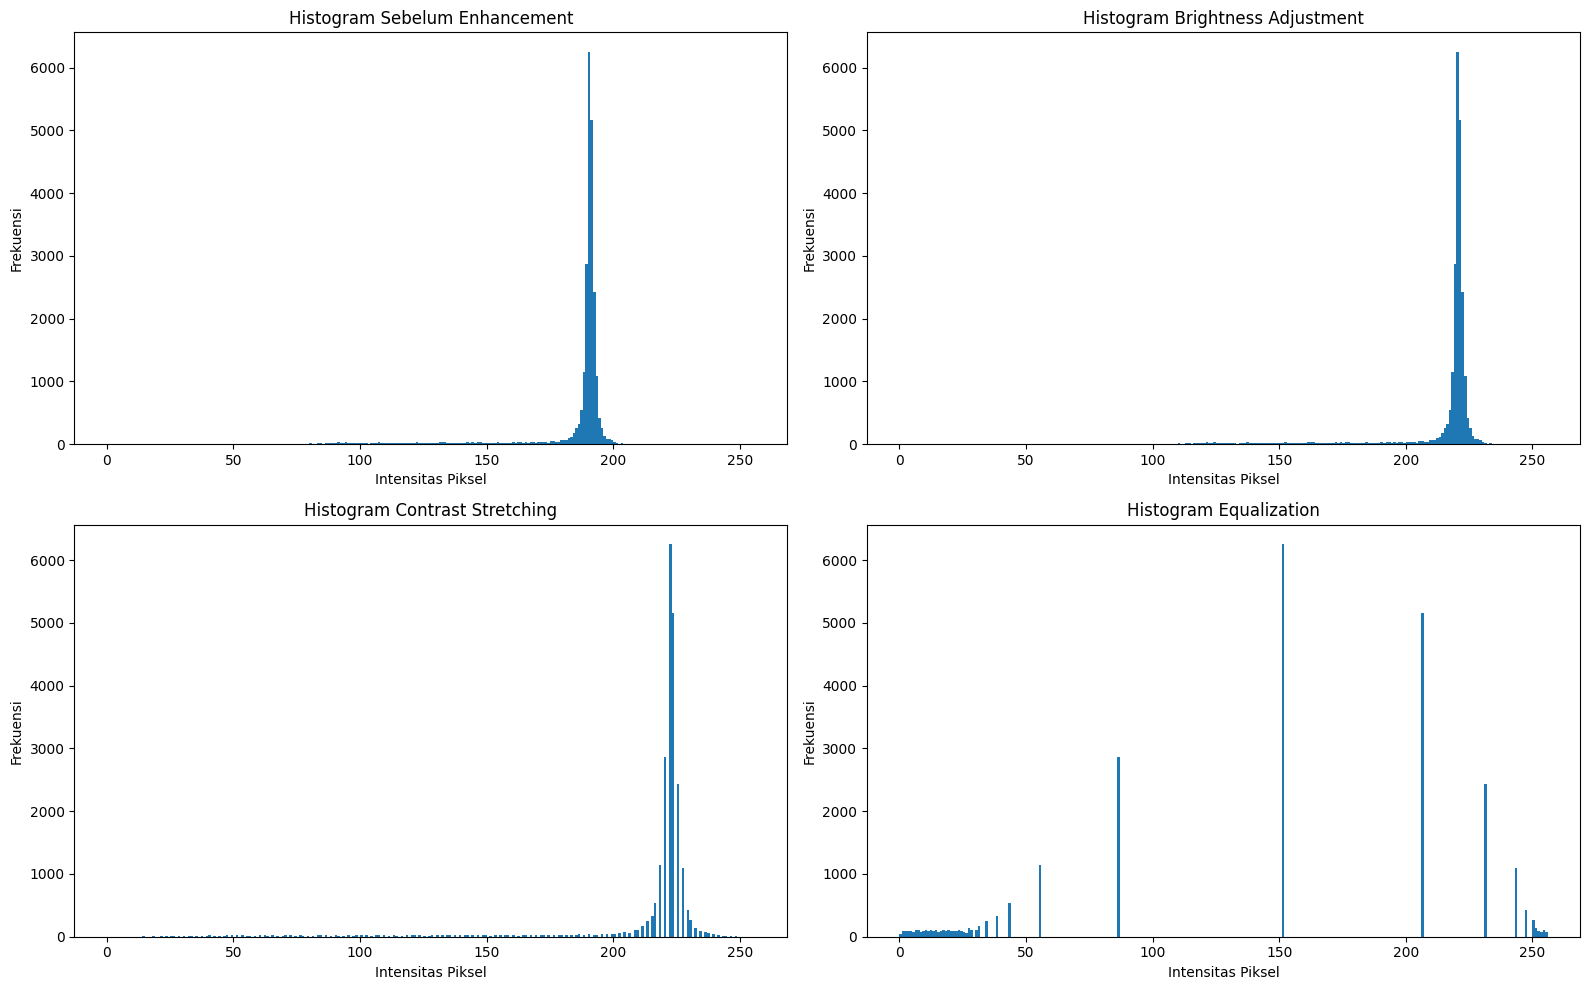

In [ ]:
# ==========================================
# 7. HISTOGRAM SEBELUM DAN SESUDAH
# ==========================================

nomor = 9 # Ganti 1-9

plt.figure(figsize=(16, 10))

# ------------------------------------------
# Histogram sebelum enhancement
# ------------------------------------------
plt.subplot(2, 2, 1)

plt.hist(
    hasil_crop[nomor].ravel(),
    bins=256,
    range=[0, 256]
)

plt.title("Histogram Sebelum Enhancement")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Frekuensi")

# ------------------------------------------
# Histogram Brightness
# ------------------------------------------
plt.subplot(2, 2, 2)

plt.hist(
    brightness_result[nomor].ravel(),
    bins=256,
    range=[0, 256]
)

plt.title("Histogram Brightness Adjustment")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Frekuensi")

# ------------------------------------------
# Histogram Contrast Stretching
# ------------------------------------------
plt.subplot(2, 2, 3)

plt.hist(
    contrast_result[nomor].ravel(),
    bins=256,
    range=[0, 256]
)

plt.title("Histogram Contrast Stretching")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Frekuensi")

# ------------------------------------------
# Histogram Equalization
# ------------------------------------------
plt.subplot(2, 2, 4)

plt.hist(
    histogram_result[nomor].ravel(),
    bins=256,
    range=[0, 256]
)

plt.title("Histogram Equalization")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Frekuensi")

plt.tight_layout()
plt.show()

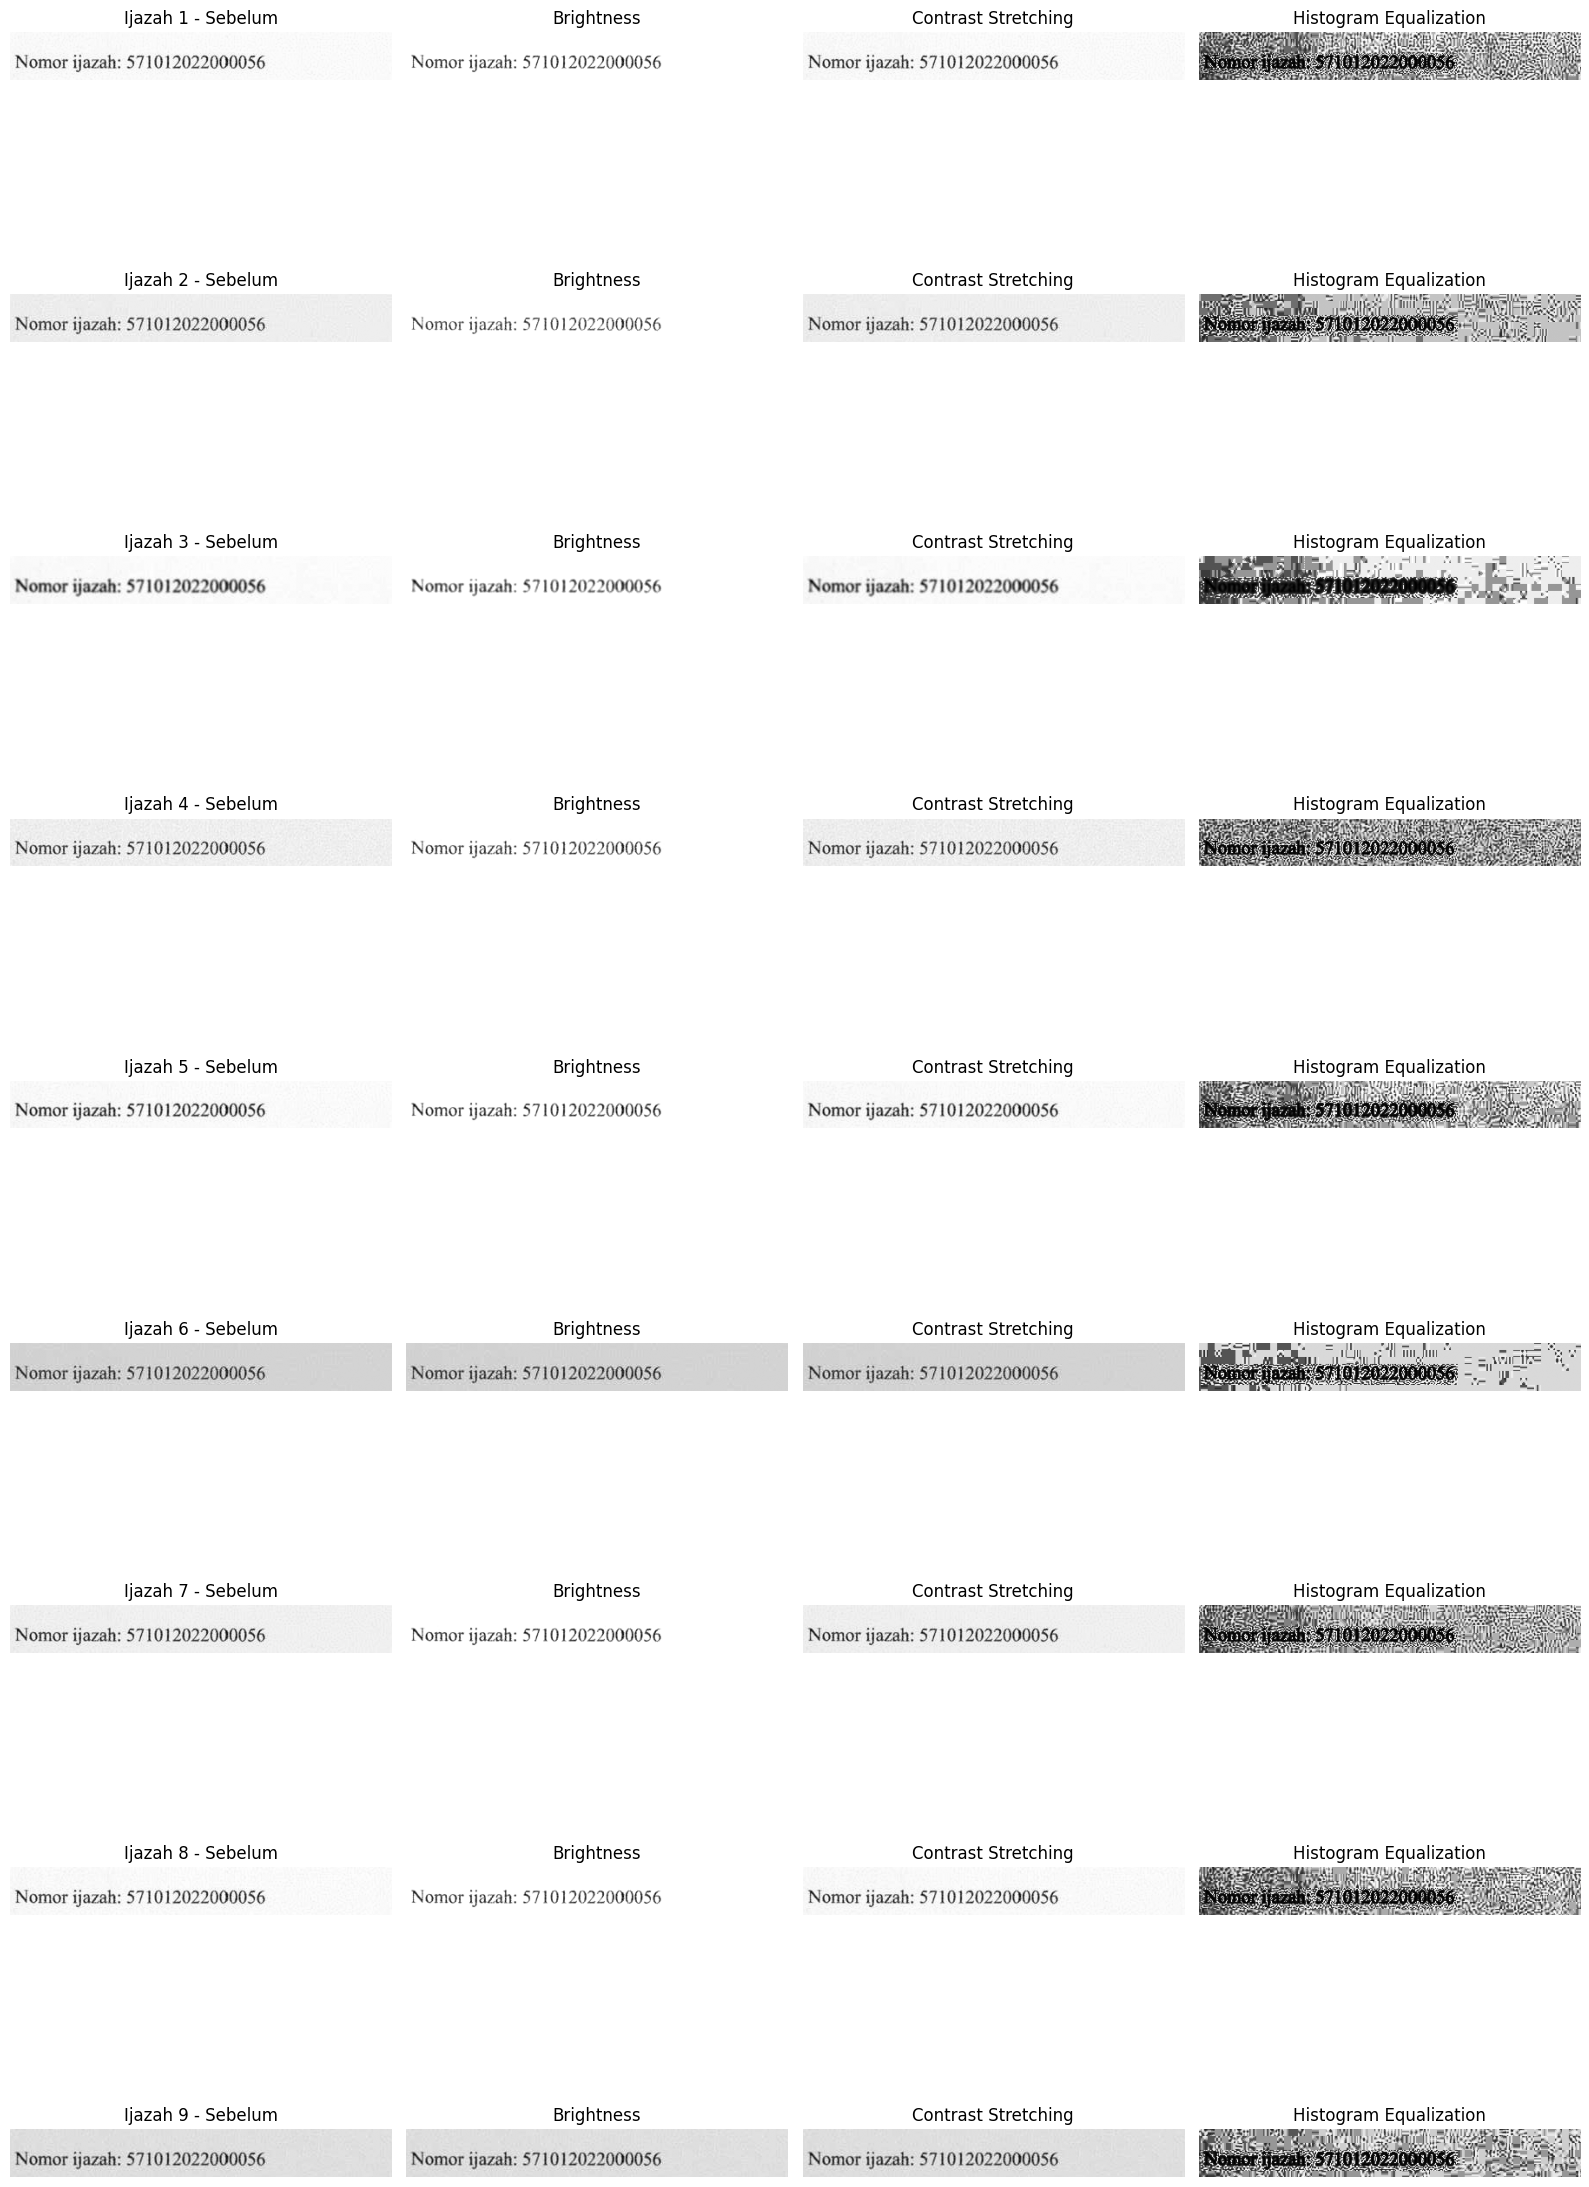

In [ ]:
# ==========================================
# 8. PERBANDINGAN SEMUA IJAZAH
# ==========================================

fig, axes = plt.subplots(9, 4, figsize=(16, 25))

for i in range(1, 10):

    # Sebelum
    axes[i-1, 0].imshow(
        hasil_crop[i],
        cmap='gray'
    )
    axes[i-1, 0].set_title(f"Ijazah {i} - Sebelum")

    # Brightness
    axes[i-1, 1].imshow(
        brightness_result[i],
        cmap='gray'
    )
    axes[i-1, 1].set_title("Brightness")

    # Contrast
    axes[i-1, 2].imshow(
        contrast_result[i],
        cmap='gray'
    )
    axes[i-1, 2].set_title("Contrast Stretching")

    # Histogram Equalization
    axes[i-1, 3].imshow(
        histogram_result[i],
        cmap='gray'
    )
    axes[i-1, 3].set_title("Histogram Equalization")

    for j in range(4):
        axes[i-1, j].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 9. OCR PADA HASIL ENHANCEMENT
# ==========================================

# Konfigurasi OCR
config_ocr = '--psm 7 -c tessedit_char_whitelist=0123456789'

hasil_ocr = []

for i in range(1, 10):

    # OCR brightness
    text_brightness = pytesseract.image_to_string(
        brightness_result[i],
        config=config_ocr
    ).strip()

    # OCR contrast stretching
    text_contrast = pytesseract.image_to_string(
        contrast_result[i],
        config=config_ocr
    ).strip()

    # OCR histogram equalization
    text_histogram = pytesseract.image_to_string(
        histogram_result[i],
        config=config_ocr
    ).strip()

    hasil_ocr.append({
        "Ijazah": i,
        "Brightness": text_brightness,
        "Contrast Stretching": text_contrast,
        "Histogram Equalization": text_histogram
    })

df_ocr = pd.DataFrame(hasil_ocr)

display(df_ocr)

,Ijazah,Brightness,Contrast Stretching,Histogram Equalization
0,1,571012022000056,571012022000056,
1,2,571012022000056,571012022000056,
2,3,571012022000056,571012022000056,
3,4,571012022000056,571012022000056,
4,5,571012022000056,571012022000056,
5,6,571012022000056,571012022000056,
6,7,571012022000056,571012022000056,
7,8,571012022000056,571012022000056,
8,9,571012022000056,571012022000056,


In [ ]:
nomor = 1

print("HASIL OCR IJAZAH", nomor)
print("=" * 50)

print("Brightness Adjustment:")
print(pytesseract.image_to_string(
    brightness_result[nomor],
    config=config_ocr
))

print("Contrast Stretching:")
print(pytesseract.image_to_string(
    contrast_result[nomor],
    config=config_ocr
))

print("Histogram Equalization:")
print(pytesseract.image_to_string(
    histogram_result[nomor],
    config=config_ocr
))

HASIL OCR IJAZAH 1
Brightness Adjustment:
571012022000056

Contrast Stretching:
571012022000056

Histogram Equalization:

